# Student Digital Life - Data Visualization

## Objective

This notebook presents the key findings from the Student Digital Life analysis using clear and meaningful visualizations. The visualizations focus on digital habits, lifestyle, well-being, academic performance, and academic failure risk.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the dataset

df = pd.read_csv("student_digital_life.csv")

print("Dataset loaded successfully.")

Dataset loaded successfully.


In [3]:
import module3_function

In [5]:
# Create social media usage category

df['Social_Media_Category'] = df[
    'Daily_Social_Media_Hours'
].apply(
    module3_function.social_media_category
)


print("Social media categories created successfully.")

Social media categories created successfully.


## 1. Distribution of Academic Performance

This visualization shows how academic performance scores are distributed across the students in the dataset.

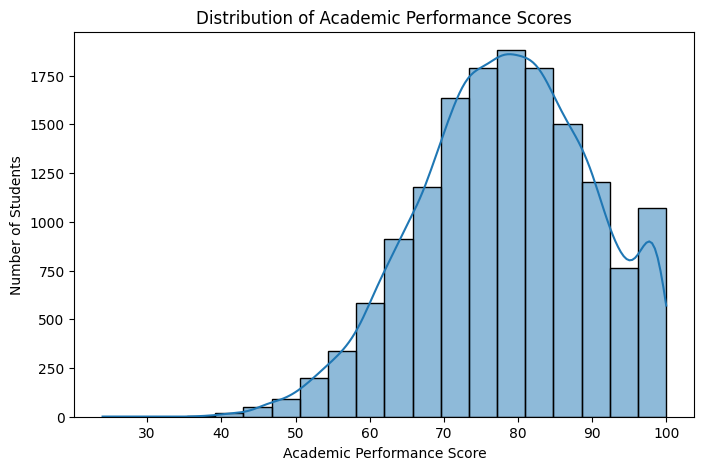

In [ ]:
# Distribution of academic performance

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='Academic_Performance_Score',
    bins=20,
    kde=True
)

plt.title('Distribution of Academic Performance Scores')
plt.xlabel('Academic Performance Score')
plt.ylabel('Number of Students')

plt.show()

## 2. Social Media Usage and Academic Performance

This visualization compares the average academic performance of students with low, moderate, and high daily social media usage.

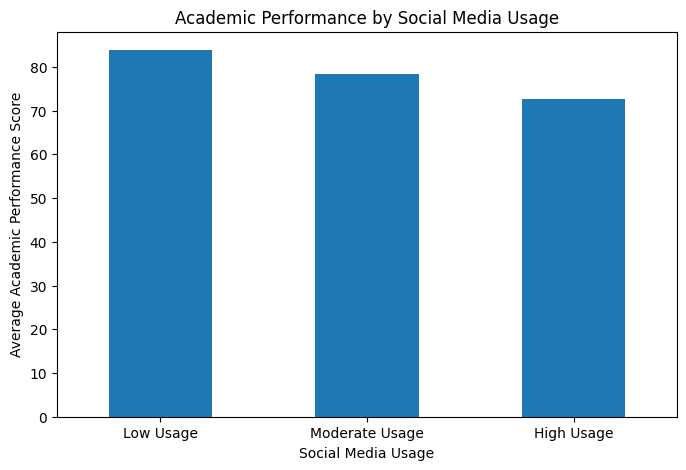

In [7]:
# Average academic performance by social media category

social_media_performance = df.groupby(
    'Social_Media_Category'
)['Academic_Performance_Score'].mean()

social_media_performance = social_media_performance.reindex([
    'Low Usage',
    'Moderate Usage',
    'High Usage'
])

plt.figure(figsize=(8, 5))

social_media_performance.plot(
    kind='bar'
)

plt.title('Academic Performance by Social Media Usage')
plt.xlabel('Social Media Usage')
plt.ylabel('Average Academic Performance Score')
plt.xticks(rotation=0)

plt.show()

## 3. Burnout Level and Academic Performance

This visualization compares average academic performance across different levels of student burnout.

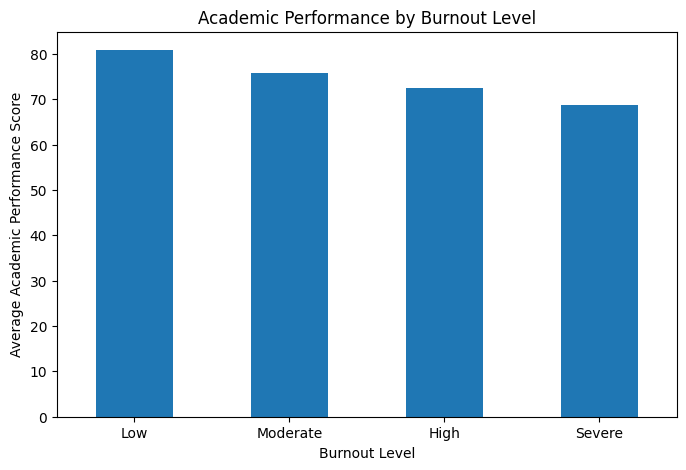

In [8]:
# Average academic performance by burnout level

burnout_performance = df.groupby(
    'Burnout_Level'
)['Academic_Performance_Score'].mean()

burnout_performance = burnout_performance.reindex([
    'Low',
    'Moderate',
    'High',
    'Severe'
])

plt.figure(figsize=(8, 5))

burnout_performance.plot(
    kind='bar'
)

plt.title('Academic Performance by Burnout Level')
plt.xlabel('Burnout Level')
plt.ylabel('Average Academic Performance Score')
plt.xticks(rotation=0)

plt.show()

## 4. Sleep and Academic Performance

This visualization examines the relationship between students' daily sleep hours and their academic performance scores.

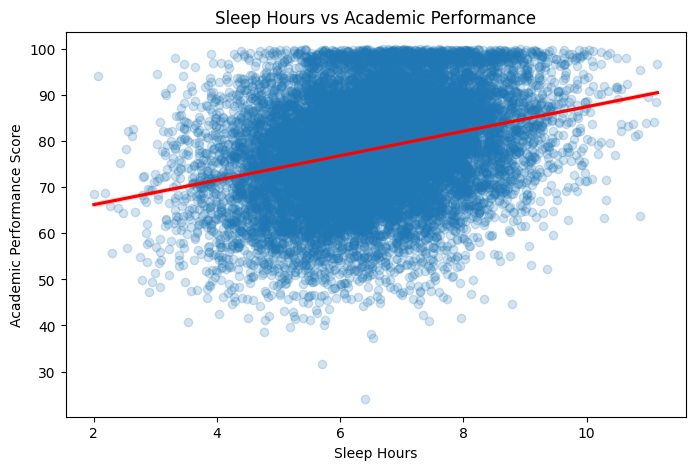

In [9]:
# Relationship between sleep and academic performance

plt.figure(figsize=(8, 5))

sns.regplot(
    data=df,
    x='Sleep_Hours',
    y='Academic_Performance_Score',
    scatter_kws={'alpha': 0.2},
    line_kws={'color': 'red'}
)

plt.title('Sleep Hours vs Academic Performance')
plt.xlabel('Sleep Hours')
plt.ylabel('Academic Performance Score')

plt.show()

## 5. Academic Failure Risk Profile

The following visualizations compare important characteristics of students with and without academic failure risk.

In [10]:
# Compare digital and lifestyle factors by academic failure risk

risk_lifestyle = df.groupby(
    'Academic_Failure_Risk'
)[
    [
        'Daily_Social_Media_Hours',
        'Daily_AI_Tool_Usage_Hours',
        'Sleep_Hours'
    ]
].mean().round(2)

risk_lifestyle.index = [
    'No Failure Risk',
    'Failure Risk'
]

risk_lifestyle

,Daily_Social_Media_Hours,Daily_AI_Tool_Usage_Hours,Sleep_Hours
No Failure Risk,4.34,2.53,6.62
Failure Risk,7.67,3.51,5.35


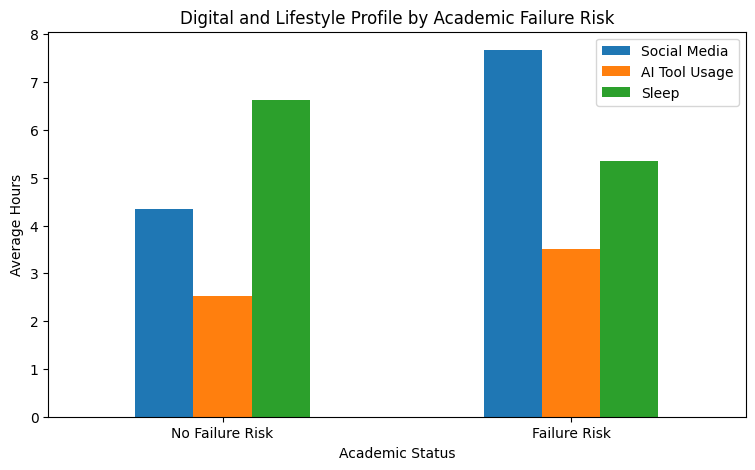

In [11]:
# Visualize digital and lifestyle differences

risk_lifestyle.plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title('Digital and Lifestyle Profile by Academic Failure Risk')
plt.xlabel('Academic Status')
plt.ylabel('Average Hours')
plt.xticks(rotation=0)
plt.legend([
    'Social Media',
    'AI Tool Usage',
    'Sleep'
])

plt.show()

In [12]:
# Compare mental health and academic performance

risk_scores = df.groupby(
    'Academic_Failure_Risk'
)[
    [
        'Mental_Health_Score',
        'Academic_Performance_Score'
    ]
].mean().round(2)

risk_scores.index = [
    'No Failure Risk',
    'Failure Risk'
]

risk_scores

,Mental_Health_Score,Academic_Performance_Score
No Failure Risk,73.34,79.18
Failure Risk,59.49,64.79


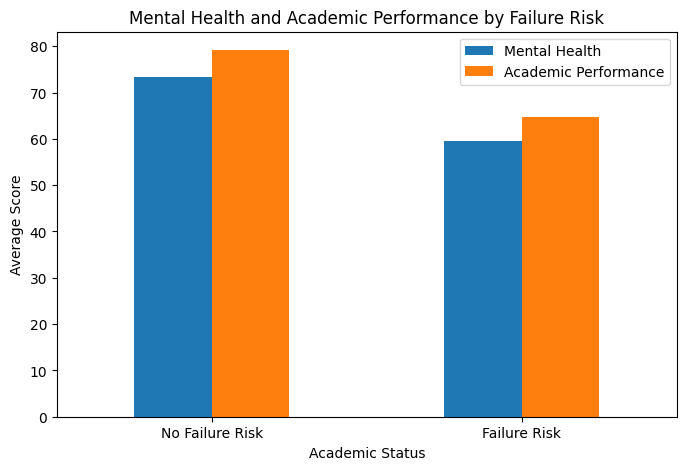

In [13]:
# Visualize score differences

risk_scores.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Mental Health and Academic Performance by Failure Risk')
plt.xlabel('Academic Status')
plt.ylabel('Average Score')
plt.xticks(rotation=0)
plt.legend([
    'Mental Health',
    'Academic Performance'
])

plt.show()

## 6. Correlation Between Student Factors

The correlation heatmap provides an overall view of the relationships between students' digital habits, lifestyle, well-being, and academic performance.

In [14]:
# Select important numerical variables

correlation_columns = [
    'Daily_Social_Media_Hours',
    'Daily_AI_Tool_Usage_Hours',
    'Sleep_Hours',
    'Physical_Activity_Hours',
    'Mental_Health_Score',
    'Physical_Health_Score',
    'Social_Isolation_Score',
    'Academic_Performance_Score'
]

correlation_matrix = df[
    correlation_columns
].corr()

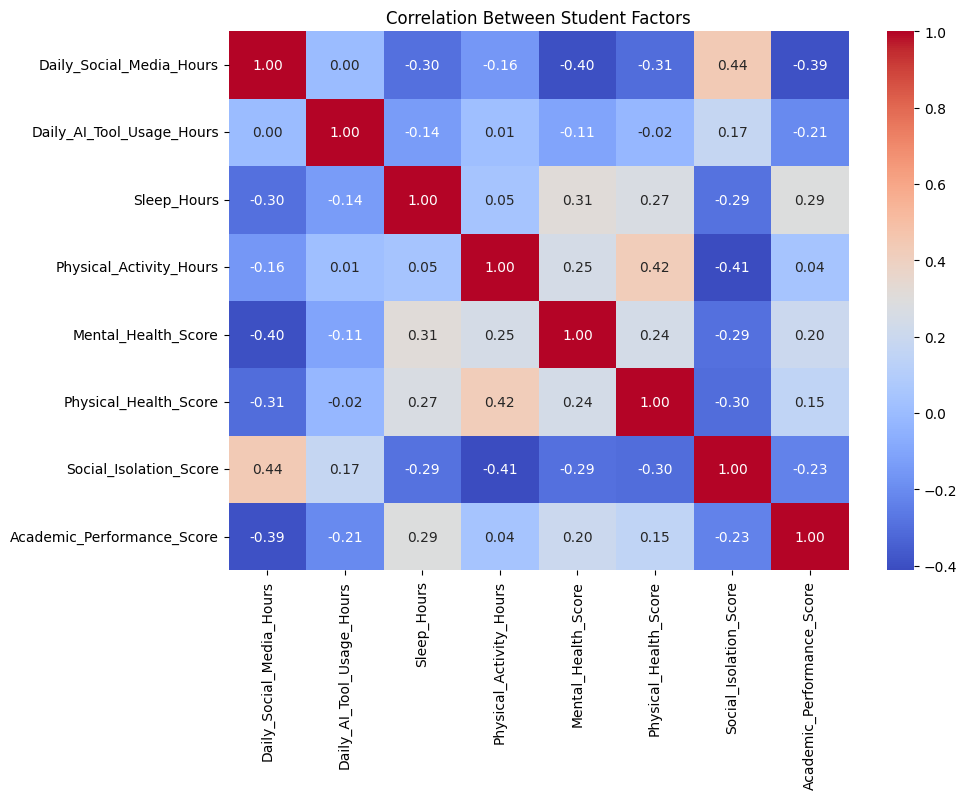

In [15]:
# Create correlation heatmap

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm'
)

plt.title('Correlation Between Student Factors')

plt.show()